# Diabetic Retinopathy using GoogLeNet Mini

## 1. Import Library

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, 
    Dense, Dropout, concatenate, BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt

I0000 00:00:1785427925.918482   26068 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785427925.982127   26068 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1785427975.510344   26068 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [3]:
BATCH_SIZE=4

In [4]:
with open("../../../data/processed/aptos/sample_50/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [5]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [6]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def create_dataset_pipeline(x_data, y_data):
    def preprocess_image(image, label):
        # Đưa ảnh về kiểu float32 và chuẩn hóa pixel về [0, 1]
        image = tf.cast(image, tf.float32) / 255.0
        return image, label

    with tf.device('/CPU:0'):
        dataset = tf.data.Dataset.from_tensor_slices((x_data, y_data))
        dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

In [10]:
train_dataset = create_dataset_pipeline(x_train, y_train)
val_dataset   = create_dataset_pipeline(x_val, y_val)
test_dataset = create_dataset_pipeline(x_test, y_test)

I0000 00:00:1785428032.264742   26068 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train

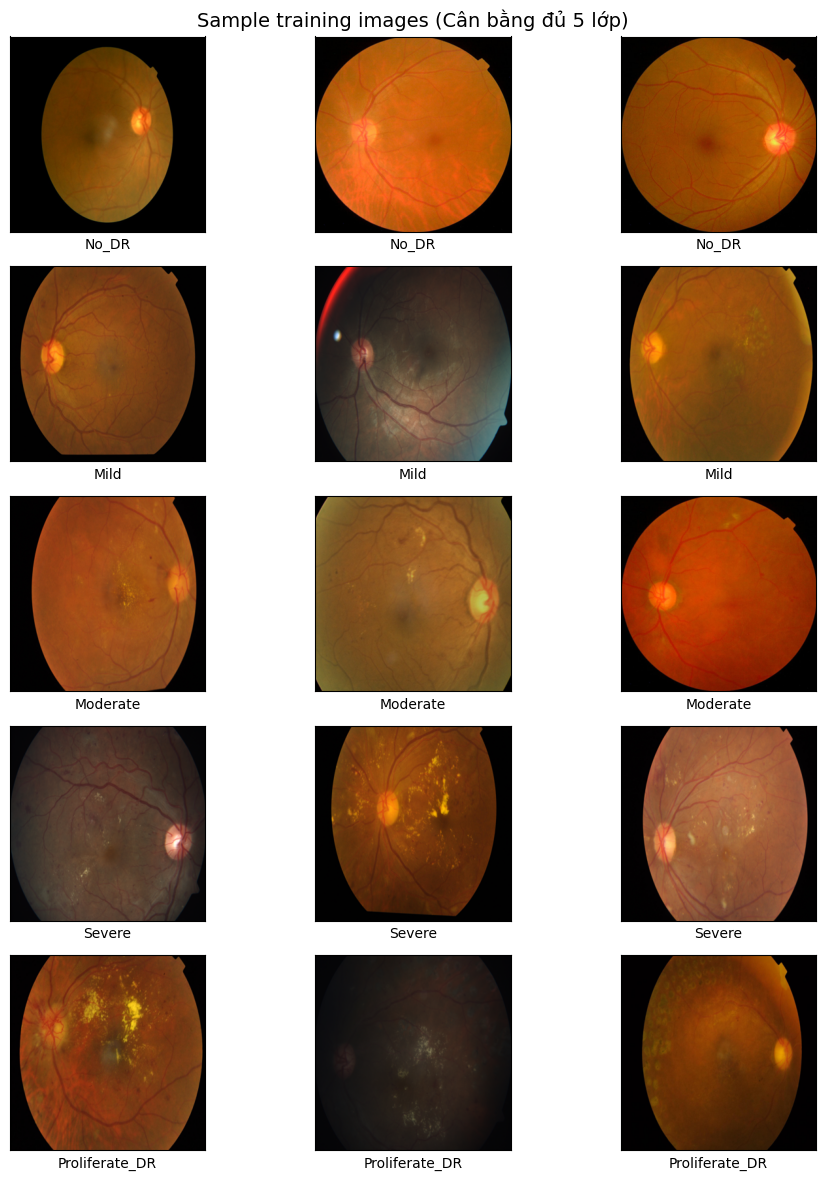

In [11]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

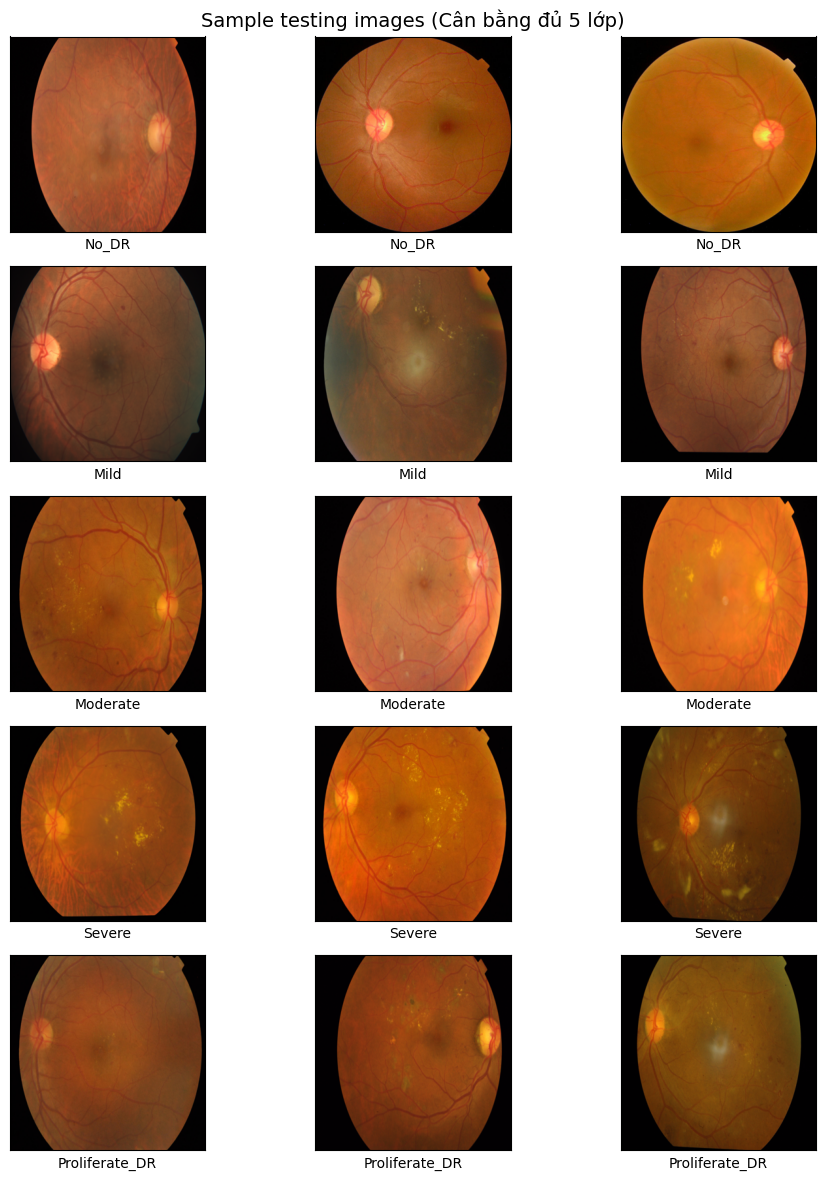

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng model GoogLeNet

In [13]:
# ==========================================
# 1. HÀM TẠO KHỐI INCEPTION (INCEPTION MODULE)
# ==========================================
def inception_module(x, filters_1x1, filters_3x3_reduce, filters_3x3, filters_5x5_reduce, filters_5x5, filters_pool_proj):
    # Nhánh 1: Tích chập 1x1
    conv_1x1 = Conv2D(filters_1x1, (1, 1), padding='same', activation='relu')(x)
    
    # Nhánh 2: Tích chập 1x1 (giảm chiều) -> Tích chập 3x3
    conv_3x3 = Conv2D(filters_3x3_reduce, (1, 1), padding='same', activation='relu')(x)
    conv_3x3 = Conv2D(filters_3x3, (3, 3), padding='same', activation='relu')(conv_3x3)
    
    # Nhánh 3: Tích chập 1x1 (giảm chiều) -> Tích chập 5x5
    conv_5x5 = Conv2D(filters_5x5_reduce, (1, 1), padding='same', activation='relu')(x)
    conv_5x5 = Conv2D(filters_5x5, (5, 5), padding='same', activation='relu')(conv_5x5)
    
    # Nhánh 4: Max Pooling -> Tích chập 1x1 (giảm chiều)
    pool_proj = MaxPooling2D((3, 3), strides=(1, 1), padding='same')(x)
    pool_proj = Conv2D(filters_pool_proj, (1, 1), padding='same', activation='relu')(pool_proj)
    
    # Gộp tất cả các nhánh lại với nhau (Concatenate) theo chiều sâu (kênh màu)
    output = concatenate([conv_1x1, conv_3x3, conv_5x5, pool_proj], axis=3)
    return output

# ==========================================
# 2. XÂY DỰNG MỘT GOOGLENET THU GỌN (MINI-GOOGLENET)
# ==========================================
def build_custom_googlenet(input_shape, num_classes):
    input_layer = Input(shape=input_shape)
    
    # Phần đầu (Stem): Trích xuất đặc trưng cơ bản
    x = Conv2D(64, (7, 7), padding='same', strides=(2, 2), activation='relu')(input_layer)
    x = MaxPooling2D((3, 3), padding='same', strides=(2, 2))(x)
    x = BatchNormalization()(x)
    
    x = Conv2D(192, (3, 3), padding='same', activation='relu')(x)
    x = MaxPooling2D((3, 3), padding='same', strides=(2, 2))(x)
    x = BatchNormalization()(x)
    
    # Lắp ghép các khối Inception (Giống với kiến trúc GoogLeNet gốc)
    # Khối Inception 3a
    x = inception_module(x, 64, 96, 128, 16, 32, 32)
    # Khối Inception 3b
    x = inception_module(x, 128, 128, 192, 32, 96, 64)
    x = MaxPooling2D((3, 3), padding='same', strides=(2, 2))(x)
    
    # Khối Inception 4a
    x = inception_module(x, 192, 96, 208, 16, 48, 64)
    
    # Phần đuôi (Classification Head)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.4)(x)
    x = Dense(1000, activation='relu')(x) # Lớp ẩn
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=input_layer, outputs=predictions, name="Custom_GoogLeNet")
    
    return model

# Gọi hàm để tạo model cho ảnh 300x300, 5 nhãn
model = build_custom_googlenet((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model.summary()

Model: "Custom_GoogLeNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 150, 150,  │      9,472 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 75, 75,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 75, 75,    │        256 │ max_pooling2d[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 75, 75,    │    110,784 │ batch_normalizat… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 38, 38,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 38, 38,    │        768 │ max_pooling2d_1[… │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 38, 38,    │     18,528 │ batch_normalizat… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 38, 38,    │      3,088 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 38, 38,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 38, 38,    │     12,352 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 38, 38,    │    110,720 │ conv2d_3[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 38, 38,    │     12,832 │ conv2d_5[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 38, 38,    │      6,176 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 38, 38,    │          0 │ conv2d_2[0][0],   │
│ (Concatenate)       │ 256)              │            │ conv2d_4[0][0],   │
│                     │                   │            │ conv2d_6[0][0],   │
│                     │                   │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 38, 38,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                 

 Total params: 1,567,893 (5.98 MB)

 Trainable params: 1,567,381 (5.98 MB)

 Non-trainable params: 512 (2.00 KB)

## 5. Compile & Train 

In [14]:
model.compile(
    optimizer=Adam(learning_rate=1e-4), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/GoogLeNet_mini_aptos_50_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785428047.289549   32797 service.cc:153] XLA service 0x7915ac059010 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785428047.289584   32797 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1785428047.414535   32797 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785428048.668693   32797 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1785428048.773902   32797 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8482__.97
I0000 00:00:1785428080.426397   32797 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1785428093.448353   32794 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.55GiB (r


Epoch 1: val_accuracy improved from None to 0.22000, saving model to ../../../data/models/GoogLeNet_mini_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/GoogLeNet_mini_aptos_50_best.keras
50/50 - 73s - 1s/step - accuracy: 0.2000 - loss: 1.6571 - val_accuracy: 0.2200 - val_loss: 1.6089 - learning_rate: 1.0000e-04
Epoch 2/100

Epoch 2: val_accuracy improved from 0.22000 to 0.26000, saving model to ../../../data/models/GoogLeNet_mini_aptos_50_best.keras

Epoch 2: finished saving model to ../../../data/models/GoogLeNet_mini_aptos_50_best.keras
50/50 - 3s - 50ms/step - accuracy: 0.2650 - loss: 1.6069 - val_accuracy: 0.2600 - val_loss: 1.6080 - learning_rate: 1.0000e-04
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.26000
50/50 - 2s - 39ms/step - accuracy: 0.3300 - loss: 1.5259 - val_accuracy: 0.2600 - val_loss: 1.6131 - learning_rate: 1.0000e-04
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.26000
50/50 - 2s - 38ms/step - accuracy: 0.3500 -

## 6. Visualize Training

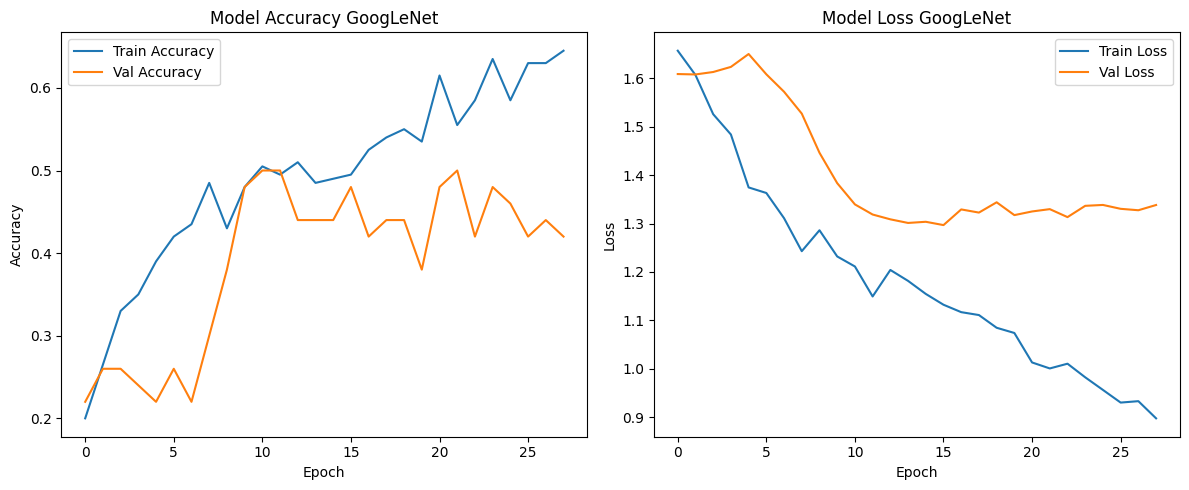

In [15]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy GoogLeNet')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss GoogLeNet')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [16]:
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}') 

Test Loss: 0.8920
Test Accuracy: 0.5956
